# Klasik Görüntü İşleme ile Mikroskobik Hücre Segmentasyonu, Sayımı ve Zamansal Analizi

**Ders:** Görüntü İşleme — Yüksek Lisans Ara Sınav Projesi
**Veri seti:** Cell Tracking Challenge — Fluo-N2DH-GOWT1 (eğitim arşivi)
**Random seed:** `31084` (öğrenci numarası son 5 hane `29058` + `2026`)

Bu notebook baştan sona sırayla çalıştırıldığında aynı veri bölünmesini, aynı deneyleri ve aynı sayısal sonuçları üretir.

> GitHub'a yüklenen sürümde veri setine ait görüntü çıktıları temizlenmiştir (ödev Bölüm 18.5).

## 0. Kurulum ve konfigürasyon

In [1]:
# Colab'da çalışıyorsak eksik paketleri kur
import sys, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'imagecodecs', 'tifffile'], check=True)

In [2]:
import os, json, time, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tifffile
import skimage
from scipy import ndimage as ndi

# ---- Sabitler ----
STUDENT_ID_LAST5 = 29058
SEED = STUDENT_ID_LAST5 + 2026          # = 31084
DATASET_URL = 'https://data.celltrackingchallenge.net/training-datasets/Fluo-N2DH-GOWT1.zip'

# ---- Klasörler ----
PROJECT_DIR = Path.cwd()
DATA_DIR    = PROJECT_DIR / 'data'                      # .gitignore'da: veri GitHub'a gitmez
DATASET_DIR = DATA_DIR / 'Fluo-N2DH-GOWT1'
FIG_DIR     = PROJECT_DIR / 'figures'                   # veri görüntüsü içermeyen grafikler
PRIVATE_FIG_DIR = PROJECT_DIR / 'figures_private'       # veri görüntüsü içeren şekiller (sadece rapor)
for d in (DATA_DIR, FIG_DIR, PRIVATE_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print('SEED =', SEED)
print('OpenCV', cv2.__version__, '| scikit-image', skimage.__version__, '| NumPy', np.__version__)

SEED = 31084
OpenCV 5.0.0 | scikit-image 0.25.2 | NumPy 2.4.6


In [3]:
# Veri seti yoksa resmi bağlantıdan indir ve aç
if not DATASET_DIR.exists():
    zip_path = DATA_DIR / 'Fluo-N2DH-GOWT1.zip'
    if not zip_path.exists():
        print('İndiriliyor...')
        urllib.request.urlretrieve(DATASET_URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)
print(sorted(p.name for p in DATASET_DIR.iterdir()))

İndiriliyor...
['01', '01_ERR_SEG', '01_GT', '01_ST', '02', '02_ERR_SEG', '02_GT', '02_ST']


In [4]:
def frame_path(seq: str, t: int) -> Path:
    """Ham görüntü yolu, ör. ('01', 5) -> .../01/t005.tif"""
    return DATASET_DIR / seq / f't{t:03d}.tif'

def read_frame(seq: str, t: int) -> np.ndarray:
    return tifffile.imread(frame_path(seq, t))

def n_frames(seq: str) -> int:
    return len(list((DATASET_DIR / seq).glob('t*.tif')))

## 1. Veri setinin ön incelemesi (Ödev Bölüm 2)

Bu bölümde **sadece ham görüntüler** (her iki sekans) ve **Sequence 01'in** referans maskeleri incelenir.
Sequence 02'nin referans anotasyonlarına (`02_GT`) test kilidine kadar dokunulmaz.

### 1.1 Boyut, veri tipi ve kare sayısı

In [5]:
rows = []
for seq in ['01', '02']:
    img = read_frame(seq, 0)
    rows.append({'Sekans': seq, 'Kare sayısı': n_frames(seq), 'Boyut': img.shape,
                 'dtype': str(img.dtype), 'Teorik aralık': f'0–{np.iinfo(img.dtype).max}'})
pd.DataFrame(rows)

,Sekans,Kare sayısı,Boyut,dtype,Teorik aralık
0,01,92,"(1024, 1024)",uint8,0–255
1,02,92,"(1024, 1024)",uint8,0–255


### 1.2 Kare bazında yoğunluk istatistikleri

In [6]:
stats = []
for seq in ['01', '02']:
    for t in range(n_frames(seq)):
        im = read_frame(seq, t).astype(np.float64)
        stats.append({'seq': seq, 't': t, 'mean': im.mean(), 'std': im.std(),
                      'min': im.min(), 'max': im.max(),
                      'p01': np.percentile(im, 1), 'p50': np.percentile(im, 50),
                      'p99': np.percentile(im, 99),
                      'frac_zero': (im == 0).mean()})
stats = pd.DataFrame(stats)
summary = stats.groupby('seq')[['mean', 'std', 'min', 'max', 'p01', 'p50', 'p99', 'frac_zero']].agg(['mean', 'min', 'max']).round(2)
summary.T

seq                 01      02
mean      mean    3.97    2.09
          min     3.63    1.72
          max     4.25    2.30
std       mean   12.54    5.61
          min    11.44    5.14
          max    14.23    5.97
min       mean    0.00    0.00
          min     0.00    0.00
          max     0.00    0.00
max       mean  219.82  126.20
          min   195.00   86.00
          max   255.00  182.00
p01       mean    0.00    0.00
          min     0.00    0.00
          max     0.00    0.00
p50       mean    0.00    0.00
          min     0.00    0.00
          max     0.00    0.00
p99       mean   67.41   31.65
          min    61.00   28.00
          max    74.00   34.00
frac_zero mean    0.57    0.62
          min     0.53    0.58
          max     0.63    0.67

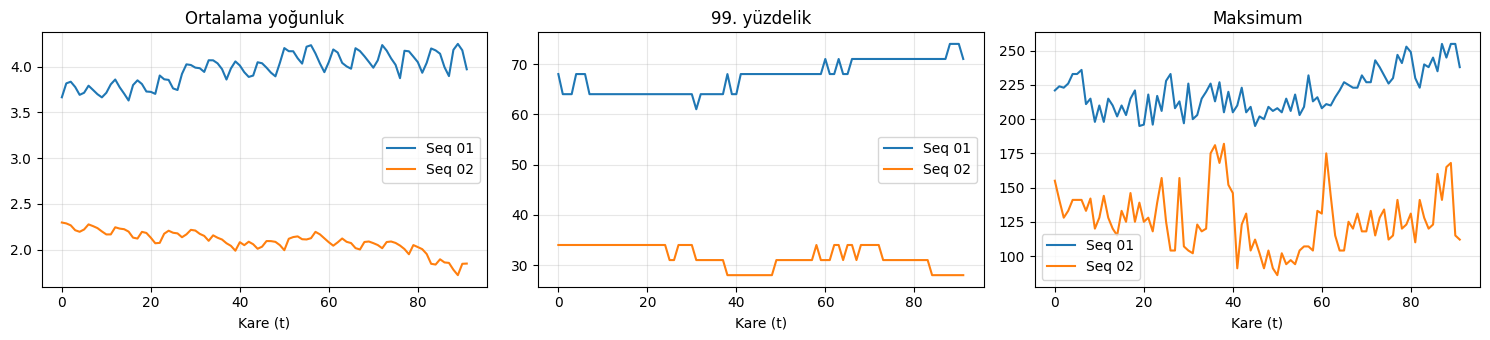

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for seq, c in [('01', 'tab:blue'), ('02', 'tab:orange')]:
    s = stats[stats.seq == seq]
    axes[0].plot(s.t, s['mean'], c=c, label=f'Seq {seq}')
    axes[1].plot(s.t, s['p99'], c=c, label=f'Seq {seq}')
    axes[2].plot(s.t, s['max'], c=c, label=f'Seq {seq}')
for ax, title in zip(axes, ['Ortalama yoğunluk', '99. yüzdelik', 'Maksimum']):
    ax.set_title(title); ax.set_xlabel('Kare (t)'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig_intensity_over_time.png', dpi=150); plt.show()

### 1.3 Örnek kareler ve histogramlar

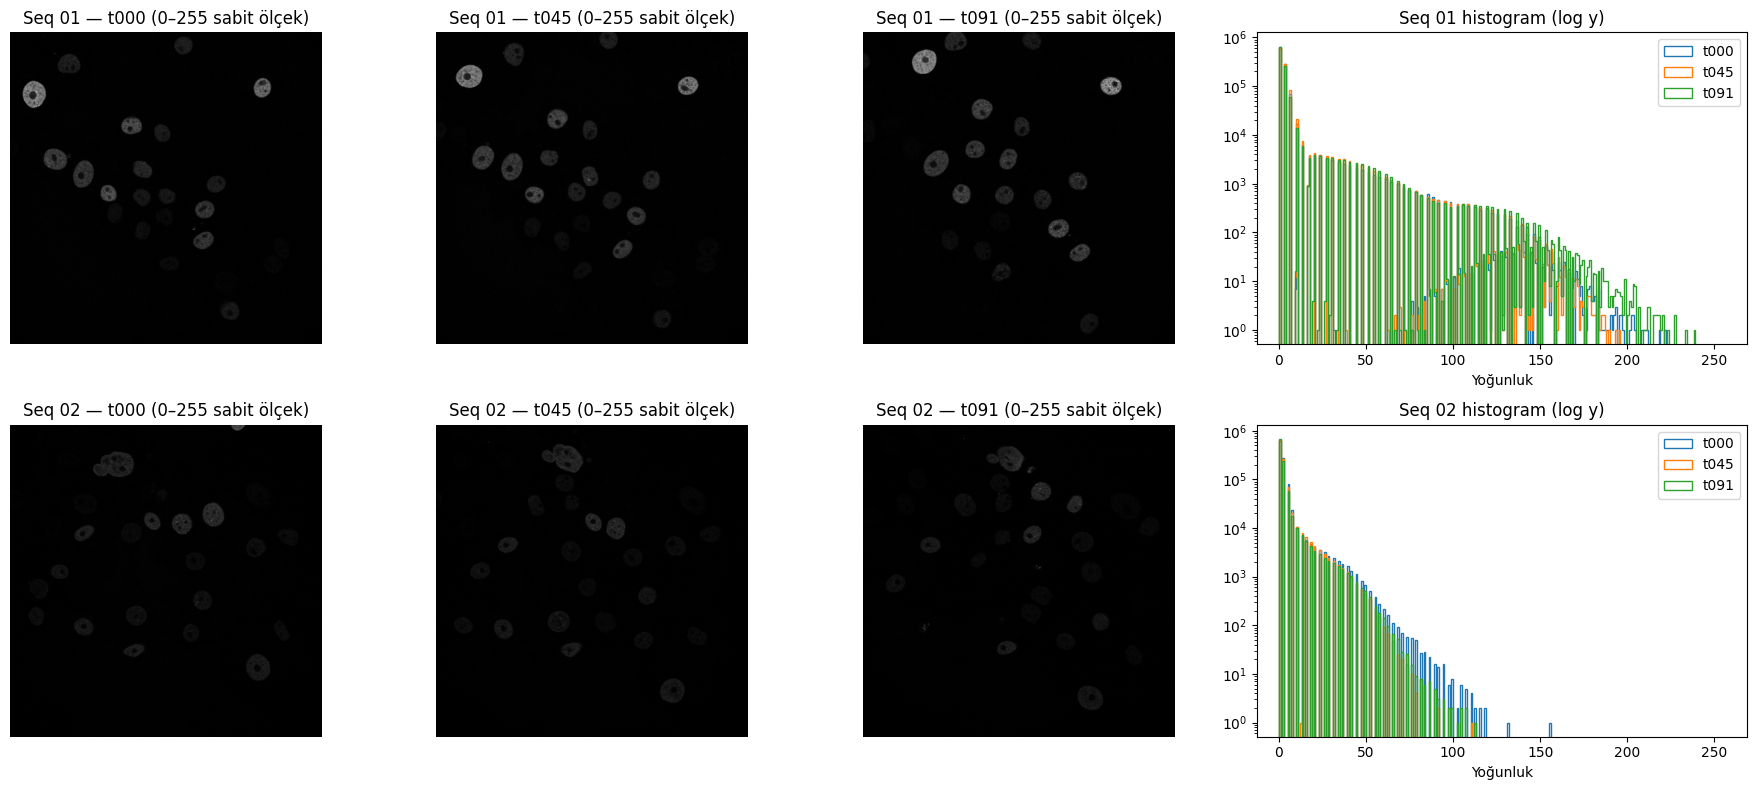

In [8]:
sample_t = [0, 45, 91]
fig, axes = plt.subplots(2, 4, figsize=(18, 8), gridspec_kw={'width_ratios': [1, 1, 1, 1.3]})
for r, seq in enumerate(['01', '02']):
    for c, t in enumerate(sample_t):
        im = read_frame(seq, t)
        axes[r, c].imshow(im, cmap='gray', vmin=0, vmax=255)
        axes[r, c].set_title(f'Seq {seq} — t{t:03d} (0–255 sabit ölçek)'); axes[r, c].axis('off')
        axes[r, 3].hist(im.ravel(), bins=256, range=(0, 256), histtype='step', log=True, label=f't{t:03d}')
    axes[r, 3].set_title(f'Seq {seq} histogram (log y)'); axes[r, 3].set_xlabel('Yoğunluk'); axes[r, 3].legend()
plt.tight_layout(); plt.savefig(PRIVATE_FIG_DIR / 'fig_samples_hist.png', dpi=120); plt.show()

### 1.4 Hücre boyutu ve temas eden hücreler (yalnızca Sequence 01 referans maskeleri)

`01_GT/SEG` klasöründe 92 karenin yalnızca 30'u için piksel düzeyinde maske vardır ve bu maskelerin çoğu **kısmidir**
(karedeki hücrelerin yalnızca bir kısmı işaretlenmiştir). Önce her SEG maskesindeki hücre sayısı aynı karenin TRA sayısıyla karşılaştırılır;
alan ve temas analizi yalnızca **tam işaretli** karelerde yapılır. Bu bilgi ileride minimum alan eşiği ve yapı elemanı boyutu için fiziksel referans olacaktır.

In [9]:
def tra_count(seq: str, t: int) -> int:
    """Referans hücre sayısı: TRA etiket görüntüsündeki farklı pozitif kimlik sayısı (Ödev Bölüm 4)."""
    lab = tifffile.imread(DATASET_DIR / f'{seq}_GT' / 'TRA' / f'man_track{t:03d}.tif')
    return int(np.count_nonzero(np.unique(lab)))

seg_files = sorted((DATASET_DIR / '01_GT' / 'SEG').glob('man_seg*.tif'))
cov = []
for f in seg_files:
    t = int(f.stem.replace('man_seg', ''))
    n_seg = int(np.count_nonzero(np.unique(tifffile.imread(f))))
    cov.append({'t': t, 'SEG hücre': n_seg, 'TRA hücre': tra_count('01', t)})
cov = pd.DataFrame(cov)
cov['tam_işaretli'] = cov['SEG hücre'] == cov['TRA hücre']
full_t = cov.loc[cov.tam_işaretli, 't'].tolist()
print(f'SEG maskeli kare: {len(cov)} | tam işaretli: {len(full_t)} -> {full_t}')
cov.T

SEG maskeli kare: 30 | tam işaretli: 4 -> [21, 31, 33, 39]


,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
t,2,5,6,7,8,10,12,13,14,15,...,33,34,37,39,40,41,44,45,46,47
SEG hücre,2,2,2,1,1,2,1,2,1,2,...,24,2,2,24,2,2,2,2,2,2
TRA hücre,23,23,23,23,23,23,23,23,23,23,...,24,24,24,24,24,24,24,24,24,25
tam_işaretli,False,False,False,False,False,False,False,False,False,False,...,True,False,False,True,False,False,False,False,False,False


In [10]:
areas, touching_rows = [], []
k = np.ones((3, 3), np.uint8)
for t in full_t:
    f = DATASET_DIR / '01_GT' / 'SEG' / f'man_seg{t:03d}.tif'
    lab = tifffile.imread(f)
    ids = [i for i in np.unique(lab) if i != 0]
    n_touch = 0
    for i in ids:
        m = (lab == i)
        areas.append(m.sum())
        ring = cv2.dilate(m.astype(np.uint8), k, iterations=2).astype(bool) & ~m
        if np.any((lab[ring] != 0) & (lab[ring] != i)):
            n_touch += 1
    touching_rows.append({'file': f.name, 'n_cells_seg': len(ids), 'n_touching': n_touch})
areas = np.array(areas)
touch = pd.DataFrame(touching_rows)
eq_diam = 2 * np.sqrt(areas / np.pi)
print(f'Analiz edilen tam işaretli kare: {len(full_t)}, hücre: {len(areas)}')
print(f'Hücre alanı (piksel): medyan={np.median(areas):.0f}, 5.yüzdelik={np.percentile(areas,5):.0f}, 95.yüzdelik={np.percentile(areas,95):.0f}, min={areas.min()}, max={areas.max()}')
print(f'Eşdeğer çap (piksel): medyan={np.median(eq_diam):.1f}, aralık={eq_diam.min():.1f}–{eq_diam.max():.1f}')
print(f'Temas eden (≤2 piksel komşu) hücre oranı: {touch.n_touching.sum() / touch.n_cells_seg.sum():.1%}')

Analiz edilen tam işaretli kare: 4, hücre: 96
Hücre alanı (piksel): medyan=2806, 5.yüzdelik=2222, 95.yüzdelik=5021, min=701, max=5306
Eşdeğer çap (piksel): medyan=59.8, aralık=29.9–82.2
Temas eden (≤2 piksel komşu) hücre oranı: 10.4%


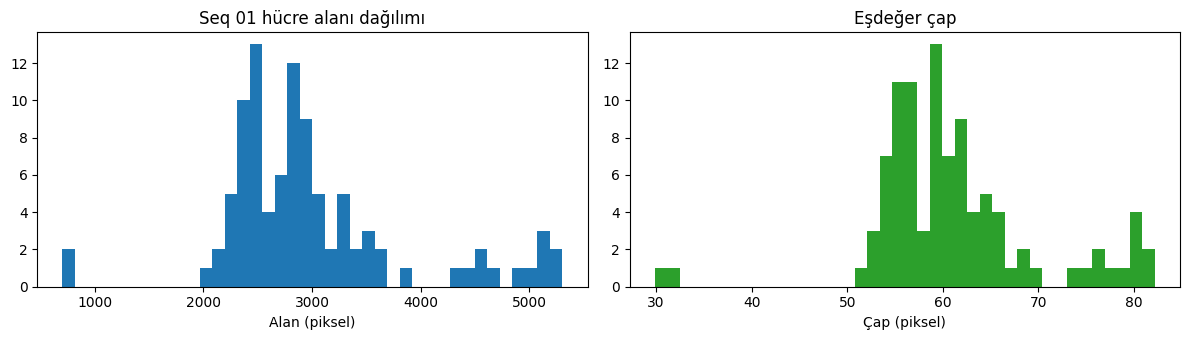

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(areas, bins=40, color='tab:blue'); axes[0].set_title('Seq 01 hücre alanı dağılımı'); axes[0].set_xlabel('Alan (piksel)')
axes[1].hist(eq_diam, bins=40, color='tab:green'); axes[1].set_title('Eşdeğer çap'); axes[1].set_xlabel('Çap (piksel)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig_cell_size_seq01.png', dpi=150); plt.show()

### 1.5 Düzensiz arka plan ve hücreler arası parlaklık farkı

Arka plan ızgara ortalaması: min=0.92, max=2.56


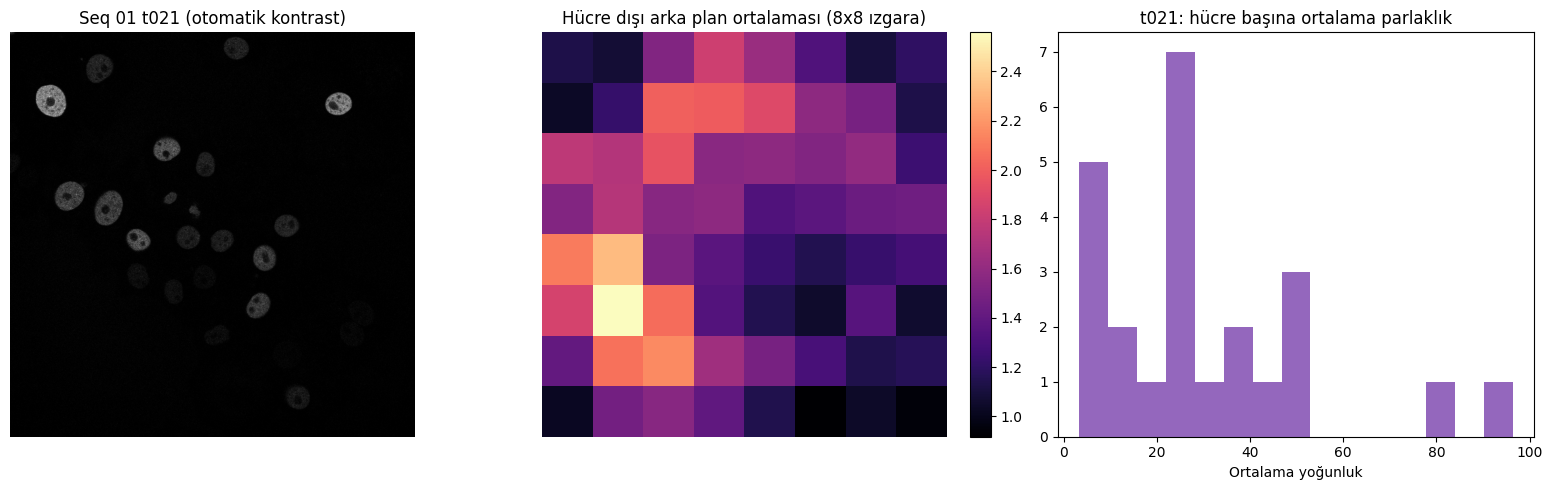

Hücre ortalama parlaklıkları: min=3.4, max=96.3  (oran ≈ 28.4x)


In [12]:
t_ex = full_t[0]
im = read_frame('01', t_ex)
lab = tifffile.imread(DATASET_DIR / '01_GT' / 'SEG' / f'man_seg{t_ex:03d}.tif')
# Arka planı ölçmek için hücreleri (genişletilmiş referans maskesi) dışarıda bırak, 8x8 ızgarada ortalama al
bg_mask = cv2.dilate((lab > 0).astype(np.uint8), np.ones((15, 15), np.uint8)) == 0
G = 8; h, w = im.shape; bg_grid = np.zeros((G, G))
for i in range(G):
    for j in range(G):
        blk = im[i*h//G:(i+1)*h//G, j*w//G:(j+1)*w//G]; m = bg_mask[i*h//G:(i+1)*h//G, j*w//G:(j+1)*w//G]
        bg_grid[i, j] = blk[m].mean() if m.any() else np.nan
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(im, cmap='gray'); axes[0].set_title(f'Seq 01 t{t_ex:03d} (otomatik kontrast)'); axes[0].axis('off')
hm = axes[1].imshow(bg_grid, cmap='magma'); plt.colorbar(hm, ax=axes[1], fraction=.046)
axes[1].set_title('Hücre dışı arka plan ortalaması (8x8 ızgara)'); axes[1].axis('off')
print(f'Arka plan ızgara ortalaması: min={np.nanmin(bg_grid):.2f}, max={np.nanmax(bg_grid):.2f}')
if lab is not None:
    means = [im[lab == i].mean() for i in np.unique(lab) if i != 0]
    axes[2].hist(means, bins=15, color='tab:purple'); axes[2].set_title(f't{t_ex:03d}: hücre başına ortalama parlaklık'); axes[2].set_xlabel('Ortalama yoğunluk')
plt.tight_layout(); plt.savefig(PRIVATE_FIG_DIR / 'fig_background_brightness.png', dpi=120); plt.show()
if lab is not None:
    print(f'Hücre ortalama parlaklıkları: min={min(means):.1f}, max={max(means):.1f}  (oran ≈ {max(means)/max(min(means),1):.1f}x)')

## 2. Geliştirme, doğrulama ve test görüntülerinin seçilmesi (Ödev Bölüm 3)

| Grup | Adet | Kaynak | Kural |
|---|---|---|---|
| Doğrulama | 5 | Seq 01 | Önce seçilir |
| Geliştirme | 10 | Seq 01 | Her doğrulama karesinden en az 5 kare boşlukla ayrılır |
| Test | 15 | Seq 02 | 3 blok × 5 ardışık kare, bloklar arasında en az 5 kare boşluk |

**"En az 5 karelik boşluk" yorumu:** İki kare arasında en az 5 kare bulunmalıdır, yani `|t_i − t_j| ≥ 6`.
Bu en katı yorumdur. Ardışık kareler neredeyse aynı göründüğü için, gruplar arası benzerlikten kaynaklanan sızıntıyı önler.

**Deterministik tekrar prosedürü:** Tek bir `numpy.random.default_rng(SEED)` üreteci kullanılır. Koşul sağlanmazsa aynı üreteçle
yeniden çekim yapılır. Böylece kaç deneme gerekirse gereksin sonuç tekrarlanabilir. Deneme sayıları kaydedilir.

Bu seçim algoritma geliştirmeden **önce** yapılmıştır ve sonradan değiştirilmez.

In [13]:
MIN_GAP = 6            # |t_i - t_j| >= 6  <=>  aralarında en az 5 kare
N_VAL, N_DEV = 5, 10
N_BLOCKS, BLOCK_LEN = 3, 5
MAX_TRIES = 10_000

rng = np.random.default_rng(SEED)
T01, T02 = n_frames('01'), n_frames('02')

# 1) Doğrulama: Seq 01'den rastgele 5 kare (ödev sırası: önce doğrulama)
val_t = sorted(rng.choice(T01, size=N_VAL, replace=False).tolist())

# 2) Geliştirme: doğrulamaya en az MIN_GAP uzaklıktaki karelerden rastgele 10 kare
dev_tries = 0
for dev_tries in range(1, MAX_TRIES + 1):
    candidates = [t for t in range(T01) if all(abs(t - v) >= MIN_GAP for v in val_t)]
    if len(candidates) >= N_DEV:
        dev_t = sorted(rng.choice(candidates, size=N_DEV, replace=False).tolist())
        break
    # Aday yetersizse doğrulama setini aynı üreteçle yeniden çek (deterministik tekrar)
    val_t = sorted(rng.choice(T01, size=N_VAL, replace=False).tolist())
else:
    raise RuntimeError('Geliştirme seçimi başarısız')

# 3) Test: Seq 02'den 3 başlangıç noktası, her biri 5 ardışık kare
#    Blok k = [s_k, s_k+4]; çakışmama + 5 kare boşluk => s_{k+1} - s_k >= BLOCK_LEN + 5
test_tries = 0
for test_tries in range(1, MAX_TRIES + 1):
    starts = sorted(rng.choice(T02 - BLOCK_LEN + 1, size=N_BLOCKS, replace=False).tolist())
    if all(b - a >= BLOCK_LEN + 5 for a, b in zip(starts, starts[1:])):
        break
else:
    raise RuntimeError('Test seçimi başarısız')

print('Doğrulama  (Seq01):', val_t)
print('Geliştirme (Seq01):', dev_t, f'| deneme={dev_tries}')
print('Test başlangıçları (Seq02):', starts, f'| deneme={test_tries}')

Doğrulama  (Seq01): [12, 53, 54, 67, 77]
Geliştirme (Seq01): [0, 1, 5, 37, 39, 44, 85, 86, 88, 89] | deneme=1
Test başlangıçları (Seq02): [33, 46, 58] | deneme=1


In [14]:
# Kural kontrolleri (assert): biri bozulursa notebook durur
assert len(set(val_t) | set(dev_t)) == N_VAL + N_DEV, 'çakışma var'
assert min(abs(d - v) for d in dev_t for v in val_t) >= MIN_GAP, 'dev-val boşluğu yetersiz'
blocks = [list(range(s, s + BLOCK_LEN)) for s in starts]
for (a, b) in zip(blocks, blocks[1:]):
    assert b[0] - a[-1] - 1 >= 5, 'test blokları arası boşluk yetersiz'
assert all(0 <= t < T02 for blk in blocks for t in blk)
print('Tüm seçim kuralları sağlandı. Dev-val minimum mesafe:',
      min(abs(d - v) for d in dev_t for v in val_t))

Tüm seçim kuralları sağlandı. Dev-val minimum mesafe: 7


In [15]:
rows = []
rows += [{'group': 'validation', 'sequence': '01', 'frame': t, 'block': ''} for t in val_t]
rows += [{'group': 'development', 'sequence': '01', 'frame': t, 'block': ''} for t in dev_t]
for k, blk in enumerate(blocks, start=1):
    rows += [{'group': 'test', 'sequence': '02', 'frame': t, 'block': f'B{k}'} for t in blk]
selected = pd.DataFrame(rows)
selected['filename'] = selected.apply(lambda r: f"{r.sequence}/t{r.frame:03d}.tif", axis=1)
selected['seed'] = SEED
selected = selected[['group', 'sequence', 'block', 'frame', 'filename', 'seed']]
selected.to_csv(PROJECT_DIR / 'selected_frames.csv', index=False)
selected.groupby('group').size()

,0
group,
development,10
test,15
validation,5


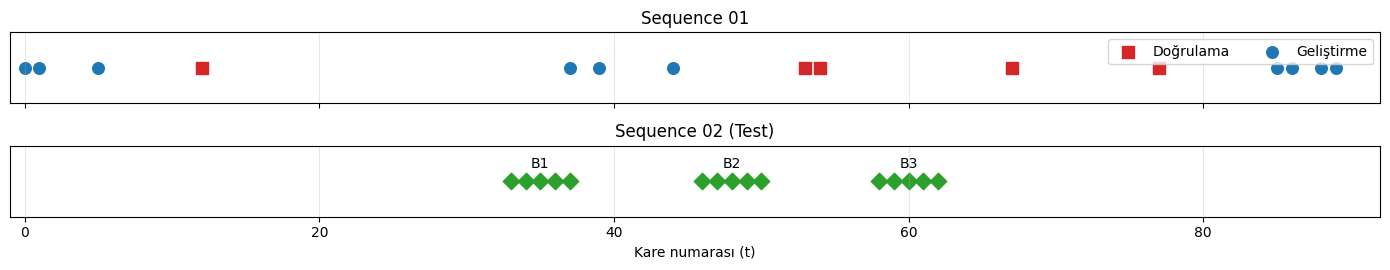

In [16]:
# Zaman ekseninde seçimlerin görünümü (veri görüntüsü içermez)
fig, axes = plt.subplots(2, 1, figsize=(14, 2.8), sharex=True)
axes[0].scatter(val_t, [0]*N_VAL, marker='s', s=70, c='tab:red', label='Doğrulama')
axes[0].scatter(dev_t, [0]*N_DEV, marker='o', s=70, c='tab:blue', label='Geliştirme')
axes[0].set_title('Sequence 01'); axes[0].legend(loc='upper right', ncol=2)
for k, blk in enumerate(blocks, 1):
    axes[1].scatter(blk, [0]*BLOCK_LEN, marker='D', s=70, c='tab:green')
    axes[1].text(np.mean(blk), 0.02, f'B{k}', ha='center')
axes[1].set_title('Sequence 02 (Test)')
for ax in axes:
    ax.set_yticks([]); ax.set_xlim(-1, max(T01, T02)); ax.grid(axis='x', alpha=.3)
axes[1].set_xlabel('Kare numarası (t)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig_selected_frames_timeline.png', dpi=150); plt.show()

## 3. Referans hücre sayıları (Ödev Bölüm 4)

Referans sayı = `XX_GT/TRA/man_trackTTT.tif` etiket görüntüsünde **sıfır hariç farklı pozitif kimlik sayısı**.
Bölüm 1.4'te görüldüğü gibi SEG maskeleri kısmi olduğu için TRA kullanılır; TRA 92 karenin tamamını kapsar.

⚠️ **Yalnızca geliştirme ve doğrulama referansları okunur.** Test (Seq 02) referansları Bölüm 10'daki kilit commit'inden sonra okunacaktır.

In [17]:
devval = selected[selected.group.isin(['development', 'validation'])].copy()
devval['ref_count'] = [tra_count(s, t) for s, t in zip(devval.sequence, devval.frame)]
devval.to_csv(PROJECT_DIR / 'reference_counts_devval.csv', index=False)
REF = {(r.sequence, r.frame): r.ref_count for r in devval.itertuples()}
devval[['group', 'frame', 'ref_count']].sort_values(['group', 'frame']).reset_index(drop=True)

,group,frame,ref_count
0,development,0,23
1,development,1,23
2,development,5,23
3,development,37,24
4,development,39,24
5,development,44,24
6,development,85,21
7,development,86,21
8,development,88,21
9,development,89,21


### 3.1 Referansların görsel kontrolü

TRA işaretçileri (marker) her hücrenin içine yerleştirilmiş küçük bölgelerdir. Her işaretçinin merkezini görüntü üzerinde gösterip,
her hücrede tam bir işaretçi olup olmadığı gözle kontrol edilir. Görüntü gamma=0.5 ile parlatılmıştır; sönük hücreler ancak böyle görülür.

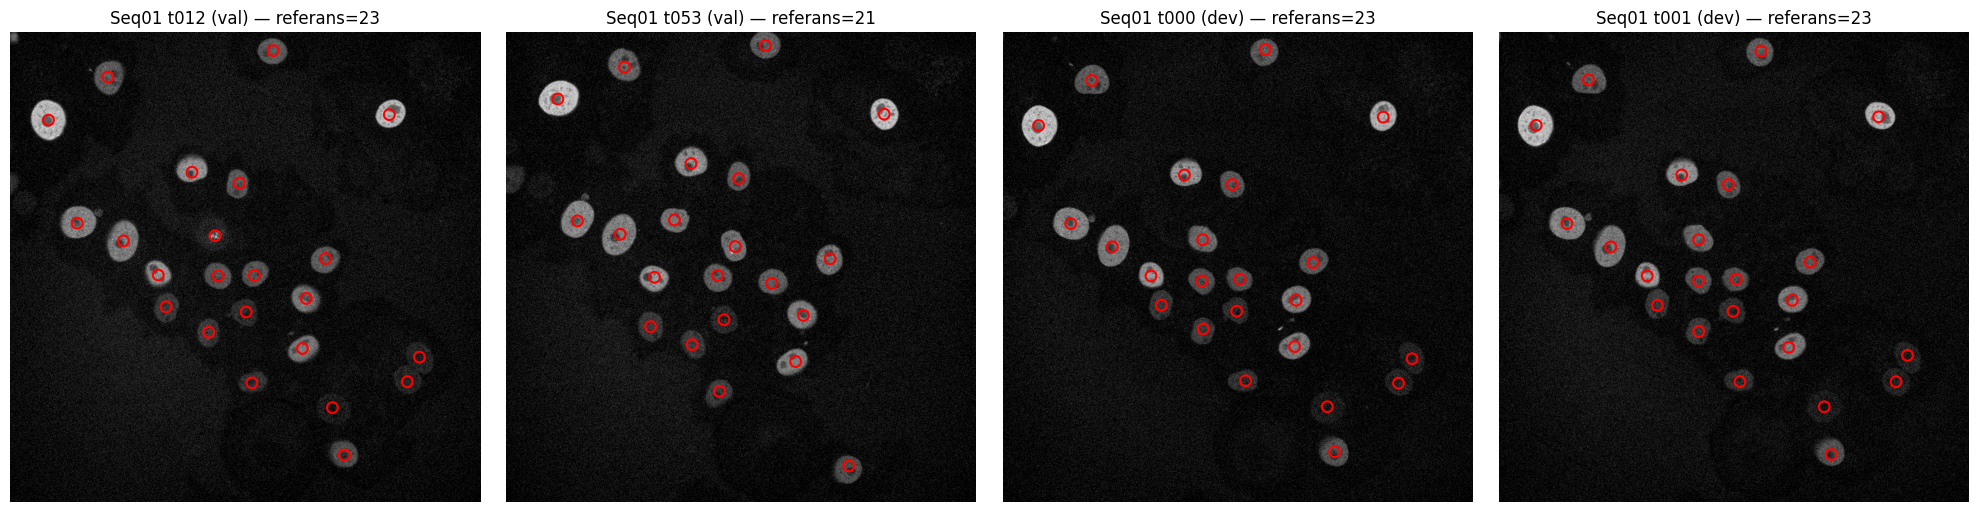

In [18]:
def tra_centroids(seq, t):
    lab = tifffile.imread(DATASET_DIR / f'{seq}_GT' / 'TRA' / f'man_track{t:03d}.tif')
    ids = [i for i in np.unique(lab) if i != 0]
    return np.array(ndi.center_of_mass(lab > 0, lab, ids))

show = val_t[:2] + dev_t[:2]
fig, axes = plt.subplots(1, len(show), figsize=(5 * len(show), 5))
for ax, t in zip(axes, show):
    im = read_frame('01', t).astype(float)
    ax.imshow((im / im.max()) ** 0.5, cmap='gray')
    cen = tra_centroids('01', t)
    ax.scatter(cen[:, 1], cen[:, 0], s=60, facecolors='none', edgecolors='red', linewidths=1.5)
    grp = 'val' if t in val_t else 'dev'
    ax.set_title(f'Seq01 t{t:03d} ({grp}) — referans={REF[("01", t)]}'); ax.axis('off')
plt.tight_layout(); plt.savefig(PRIVATE_FIG_DIR / 'fig_reference_check.png', dpi=110); plt.show()

## 4. Baseline yöntemi (Ödev Bölüm 5)

**Akış:** ham gri görüntü → global Otsu eşikleme → 8-komşuluklu bağlı bileşen etiketleme → minimum alan filtresi → sayım.

Ödevin izin verdiği tek ayar, **geliştirme verileri üzerinde belirlenen sabit bir minimum nesne alanı eşiğidir**.
Bu eşik 0–800 piksel aralığında 10 piksel adımla taranır ve geliştirme MAE'sini en düşük yapan değer seçilir
(eşitlik olursa küçük olan). Seçim kuralı, sonraki tüm deneylerle tutarlı olsun diye MAE'dir.
Baseline bu bölümden sonra **dondurulur**.

In [19]:
def count_components(binary: np.ndarray, min_area: int = 0, connectivity: int = 8):
    """İkili maskede bağlı bileşenleri bulur; min_area'dan küçükleri atar.
    Dönüş: (sayı, etiket görüntüsü [atılanlar 0], alanlar)"""
    n, lab, st, _ = cv2.connectedComponentsWithStats(binary.astype(np.uint8), connectivity=connectivity)
    areas = st[1:, cv2.CC_STAT_AREA]
    keep = np.zeros(n, bool); keep[1:] = areas >= min_area
    remap = np.zeros(n, np.int32); remap[keep] = np.arange(1, keep.sum() + 1)
    return int(keep.sum()), remap[lab], areas[areas >= min_area]

def baseline_segment(img: np.ndarray):
    """Baseline: global Otsu. Dönüş: (ikili maske, Otsu eşiği)"""
    th, b = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return b > 0, th

def count_metrics(pred, ref):
    e = np.asarray(pred, float) - np.asarray(ref, float)
    return {'MAE': np.abs(e).mean(), 'RMSE': np.sqrt((e ** 2).mean()), 'Bias': e.mean(),
            'ExactAcc': (e == 0).mean()}

def match_stats(lab: np.ndarray, seq: str, t: int):
    """Sayımın arkasını açar: tespitler referans işaretçileriyle nasıl eşleşiyor?
    - hit_cells: en az bir tespitin örtüştüğü farklı referans hücre sayısı
    - empty: hiçbir işaretçiyle örtüşmeyen tespit (yanlış pozitif)
    - extra: her hücre için (üzerine düşen tespit − 1) toplamı (parçalanma)
    - merged: birden fazla hücre içeren tespit (birleşme)"""
    tra = tifffile.imread(DATASET_DIR / f'{seq}_GT' / 'TRA' / f'man_track{t:03d}.tif')
    per_cell = {}                     # referans hücre -> üzerine düşen tespit sayısı
    empty = merged = 0
    for k in range(1, lab.max() + 1):
        ids = np.unique(tra[lab == k]); ids = ids[ids > 0]
        if len(ids) == 0: empty += 1
        merged += len(ids) > 1
        for i in ids: per_cell[i] = per_cell.get(i, 0) + 1
    n_ref = int(np.count_nonzero(np.unique(tra)))
    return {'hit_cells': len(per_cell), 'missed': n_ref - len(per_cell), 'empty': empty,
            'extra': int(sum(v - 1 for v in per_cell.values())), 'merged': int(merged)}

### 4.1 Minimum alan eşiğinin geliştirme verisinde belirlenmesi

In [20]:
dev_frames = sorted(devval.loc[devval.group == 'development', 'frame'])
val_frames = sorted(devval.loc[devval.group == 'validation', 'frame'])

# Otsu maskeleri bir kez hesaplanır, farklı min_area değerleri bunlar üzerinde denenir
dev_masks = {t: baseline_segment(read_frame('01', t))[0] for t in dev_frames}
grid = list(range(0, 801, 10))
sweep = []
for A in grid:
    preds = [count_components(dev_masks[t], A)[0] for t in dev_frames]
    m = count_metrics(preds, [REF[('01', t)] for t in dev_frames])
    sweep.append({'min_area': A, **m})
sweep = pd.DataFrame(sweep)
BASELINE_MIN_AREA = int(sweep.loc[sweep.MAE.idxmin(), 'min_area'])   # idxmin eşitlikte ilkini (küçüğü) alır
print('Seçilen BASELINE_MIN_AREA =', BASELINE_MIN_AREA)
sweep[sweep.min_area.isin([0, 10, 20, 30, 40, 50, 100, 200, 300, 500, 800])].round(2)

Seçilen BASELINE_MIN_AREA = 30


,min_area,MAE,RMSE,Bias,ExactAcc
0,0,834.5,846.99,834.5,0.0
1,10,40.3,40.99,40.3,0.0
2,20,10.8,12.37,9.8,0.0
3,30,5.5,6.30,0.9,0.0
4,40,5.7,7.16,-1.9,0.1
5,50,6.5,8.02,-4.1,0.1
10,100,8.5,9.31,-8.5,0.0
20,200,10.6,10.85,-10.6,0.0
30,300,11.0,11.20,-11.0,0.0
50,500,12.0,12.15,-12.0,0.0


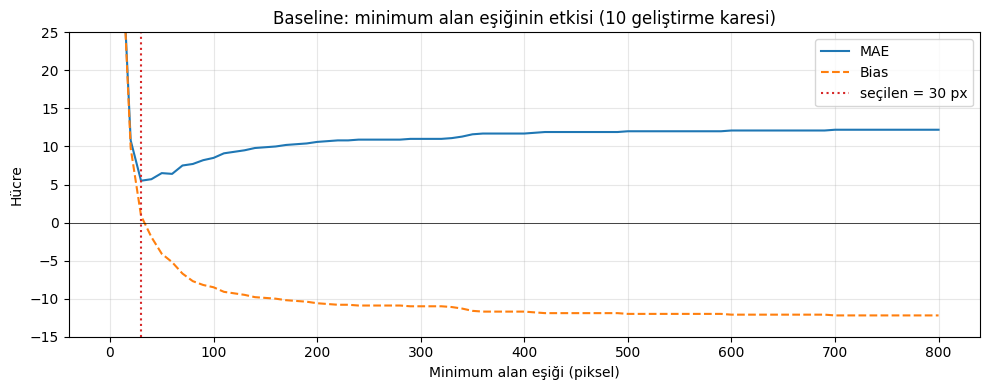

In [21]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sweep.min_area, sweep.MAE, label='MAE'); ax.plot(sweep.min_area, sweep.Bias, ls='--', label='Bias')
ax.axhline(0, c='k', lw=.5); ax.axvline(BASELINE_MIN_AREA, c='tab:red', ls=':', label=f'seçilen = {BASELINE_MIN_AREA} px')
ax.set_ylim(-15, 25); ax.set_xlabel('Minimum alan eşiği (piksel)'); ax.set_ylabel('Hücre')
ax.set_title('Baseline: minimum alan eşiğinin etkisi (10 geliştirme karesi)'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig_baseline_minarea_sweep.png', dpi=150); plt.show()

In [22]:
# Baseline dondurulur: parametreler dosyaya yazılır ve bundan sonra değiştirilmez
BASELINE = {'name': 'baseline_otsu_cc', 'steps': ['gray', 'global_otsu', 'connected_components_8', 'min_area_filter'],
            'min_area': BASELINE_MIN_AREA, 'connectivity': 8,
            'min_area_selection': 'argmin development MAE over 0..800 step 10'}
(PROJECT_DIR / 'configs').mkdir(exist_ok=True)
with open(PROJECT_DIR / 'configs' / 'baseline.json', 'w') as f:
    json.dump(BASELINE, f, indent=2)

def run_baseline(img):
    b, th = baseline_segment(img)
    n, lab, _ = count_components(b, BASELINE['min_area'], BASELINE['connectivity'])
    return n, lab, b, th
BASELINE

{'name': 'baseline_otsu_cc',
 'steps': ['gray', 'global_otsu', 'connected_components_8', 'min_area_filter'],
 'min_area': 30,
 'connectivity': 8,
 'min_area_selection': 'argmin development MAE over 0..800 step 10'}

### 4.2 Baseline sonuçları (geliştirme + doğrulama)

In [23]:
rows = []
for grp, frames in [('development', dev_frames), ('validation', val_frames)]:
    for t in frames:
        img = read_frame('01', t)
        t0 = time.perf_counter(); n, lab, b, th = run_baseline(img); dt = time.perf_counter() - t0
        rows.append({'group': grp, 'frame': t, 'ref': REF[('01', t)], 'pred': n, 'otsu_th': th,
                     'n_components_raw': count_components(b, 0)[0], 'time_s': dt, **match_stats(lab, '01', t)})
base_res = pd.DataFrame(rows)
base_res['error'] = base_res.pred - base_res.ref
base_res.to_csv(PROJECT_DIR / 'baseline_results_devval.csv', index=False)
base_res

,group,frame,ref,pred,otsu_th,n_components_raw,time_s,hit_cells,missed,empty,extra,merged,error
0,development,0,23,12,34.0,1048,0.017731,10,13,1,1,0,-11
1,development,1,23,18,35.0,1049,0.019565,11,12,0,7,0,-5
2,development,5,23,17,35.0,1069,0.019047,11,12,2,4,0,-6
3,development,37,24,27,30.0,952,0.019488,16,8,0,11,0,3
4,development,39,24,23,30.0,777,0.021698,15,9,1,7,0,-1
5,development,44,24,29,31.0,781,0.020127,16,8,0,13,0,5
6,development,85,21,26,34.0,729,0.017558,15,6,2,9,0,5
7,development,86,21,26,34.0,695,0.019454,15,6,0,11,0,5
8,development,88,21,24,37.0,745,0.016686,14,7,0,10,0,3
9,development,89,21,32,37.0,725,0.019066,15,6,2,15,0,11


In [24]:
summ = []
for grp in ['development', 'validation']:
    d = base_res[base_res.group == grp]
    summ.append({'Küme': grp, **{k: round(v, 3) for k, v in count_metrics(d.pred, d.ref).items()},
                 'Bulunan hücre': f"{d['hit_cells'].sum()}/{d['ref'].sum()}", 'Parçalanma (fazla)': d['extra'].sum(),
                 'Boş tespit': d['empty'].sum(), 'Birleşme': d['merged'].sum(), 'Ort. süre (ms)': round(d.time_s.mean() * 1000, 1)})
pd.DataFrame(summ)

,Küme,MAE,RMSE,Bias,ExactAcc,Bulunan hücre,Parçalanma (fazla),Boş tespit,Birleşme,Ort. süre (ms)
0,development,5.5,6.301,0.9,0.0,138/225,88,8,0,19.0
1,validation,10.2,11.054,6.2,0.0,76/107,59,3,0,20.1


**Yorum notu:** Düşük Bias'ın sebebi algoritmanın iyi olması değil, iki zıt hatanın birbirini götürmesidir.
Kaçırılan sönük hücreler (eksik sayım) ile orta parlaklıktaki hücrelerin parçalanmasından gelen fazladan tespitler (fazla sayım) birbirini dengeler.
Bu nedenle sonraki deneylerde MAE'nin yanında eşleşme tablosu da raporlanacaktır.

### 4.3 Baseline ara çıktıları (Şekil 4 için)

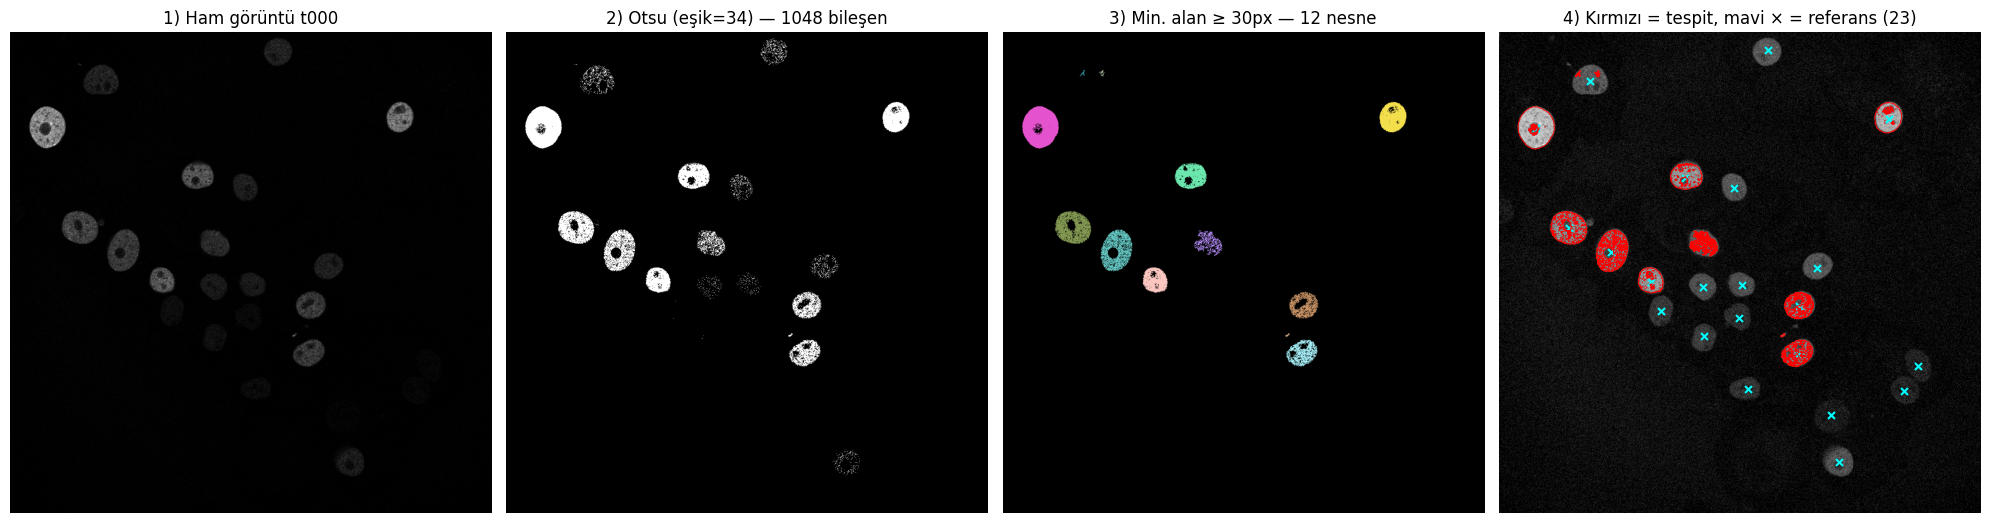

In [25]:
t = dev_frames[0]
img = read_frame('01', t); n, lab, b, th = run_baseline(img)
rng_c = np.random.default_rng(0); cols = rng_c.uniform(.3, 1, (lab.max() + 1, 3)); cols[0] = 0
fig, axes = plt.subplots(1, 4, figsize=(20, 5.5))
axes[0].imshow(img, cmap='gray'); axes[0].set_title(f'1) Ham görüntü t{t:03d}')
axes[1].imshow(b, cmap='gray'); axes[1].set_title(f'2) Otsu (eşik={th:.0f}) — {count_components(b, 0)[0]} bileşen')
axes[2].imshow(cols[lab]); axes[2].set_title(f'3) Min. alan ≥ {BASELINE_MIN_AREA}px — {n} nesne')
axes[3].imshow((img / img.max()) ** .5, cmap='gray'); axes[3].contour(lab > 0, colors='red', linewidths=.6)
cen = tra_centroids('01', t); axes[3].scatter(cen[:, 1], cen[:, 0], s=25, c='cyan', marker='x')
axes[3].set_title(f'4) Kırmızı = tespit, mavi × = referans ({REF[("01", t)]})')
for a in axes: a.axis('off')
plt.tight_layout(); plt.savefig(PRIVATE_FIG_DIR / 'fig_baseline_stages.png', dpi=110); plt.show()

## 5. Deney altyapısı

Tüm deneyler aynı `run_pipeline(config)` fonksiyonuyla çalışır. Bir konfigürasyon dört adımdan oluşur:
**yoğunluk dönüşümü → filtre → segmentasyon → morfoloji/ayırma**, ardından bağlı bileşen + minimum alan filtresiyle sayım.

Kontrollü karşılaştırma için her deney grubunda **yalnızca bir adım değiştirilir**; diğer adımlar baseline'daki gibi kalır
(Otsu, filtre yok, morfoloji yok, min alan 30 px). Her deney `experiments.csv`'ye bir satır olarak yazılır.
Tüm deneyler yalnızca **10 geliştirme karesinde** değerlendirilir.

In [26]:
# ---------- Yoğunluk dönüşümleri ----------
def t_stretch(img, p_lo=1, p_hi=99.8):
    lo, hi = np.percentile(img, [p_lo, p_hi])
    return np.clip((img.astype(np.float32) - lo) / max(hi - lo, 1e-6) * 255, 0, 255).astype(np.uint8)

def t_gamma(img, g=0.5):
    return (np.power(img.astype(np.float32) / 255.0, g) * 255).astype(np.uint8)

def t_he(img):
    return cv2.equalizeHist(img)

def t_clahe(img, clip=2.0, tile=8):
    return cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(img)

INTENSITY = {'none': lambda img, **k: img, 'stretch': t_stretch, 'gamma': t_gamma, 'he': t_he, 'clahe': t_clahe}

# ---------- Filtreler (Bölüm 6'da genişletilecek) ----------
FILTERS = {'none': lambda img, **k: img}

# ---------- Segmentasyon (Bölüm 7'de genişletilecek) ----------
def s_otsu(img):
    _, b = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return b > 0
SEGMENT = {'otsu': lambda img, **k: s_otsu(img)}

# ---------- Morfoloji / ayırma (Bölüm 8'de genişletilecek) ----------
MORPH = {}

def run_pipeline(img, cfg, return_stages=False):
    """cfg = {'intensity': (ad, {param}), 'filter': (ad, {param}), 'segment': (ad, {param}),
             'morph': [(işlem, {param}), ...], 'min_area': int}
    Dönüş: (sayı, etiket görüntüsü[, ara aşamalar])"""
    st = {'raw': img}
    x = INTENSITY[cfg['intensity'][0]](img, **cfg['intensity'][1]); st['intensity'] = x
    x = FILTERS[cfg['filter'][0]](x, **cfg['filter'][1]);           st['filter'] = x
    b = SEGMENT[cfg['segment'][0]](x, **cfg['segment'][1]);         st['binary'] = b
    lab = None
    for op, p in cfg.get('morph', []):
        b, lab = MORPH[op](b, x, **p)
    st['morph'] = b
    if lab is None:
        n, lab, _ = count_components(b, cfg['min_area'])
    else:                                     # ayırma işlemi kendi etiketlerini üretti
        n, lab = filter_labels_by_area(lab, cfg['min_area'])
    return (n, lab, st) if return_stages else (n, lab)

def filter_labels_by_area(lab, min_area):
    ids, areas = np.unique(lab[lab > 0], return_counts=True)
    keep = ids[areas >= min_area]
    remap = np.zeros(lab.max() + 1, np.int32); remap[keep] = np.arange(1, len(keep) + 1)
    return len(keep), remap[lab]

BASE_CFG = {'intensity': ('none', {}), 'filter': ('none', {}), 'segment': ('otsu', {}), 'morph': [], 'min_area': BASELINE_MIN_AREA}

def cfg_with(**changes):
    import copy
    c = copy.deepcopy(BASE_CFG); c.update(changes); return c

def fmt_step(step):
    name, p = step
    return name if not p else f"{name}(" + ', '.join(f'{k}={v}' for k, v in p.items()) + ')'

EXPERIMENTS = []
DEV_IMGS = {t: read_frame('01', t) for t in dev_frames}

def evaluate(cfg, frames=None, imgs=None, seq='01'):
    frames = frames or dev_frames; imgs = imgs or DEV_IMGS
    preds, ms, times = [], [], []
    for t in frames:
        t0 = time.perf_counter(); n, lab = run_pipeline(imgs[t], cfg); times.append(time.perf_counter() - t0)
        preds.append(n); ms.append(match_stats(lab, seq, t))
    refs = [REF[(seq, t)] for t in frames]
    m = count_metrics(preds, refs); ms = pd.DataFrame(ms)
    return {**m, 'found': int(ms.hit_cells.sum()), 'n_ref': int(sum(refs)), 'extra': int(ms.extra.sum()),
            'empty': int(ms['empty'].sum()), 'merged': int(ms.merged.sum()), 'time_ms': 1000 * np.mean(times), 'preds': preds}

def log_experiment(exp_id, group, cfg, note=''):
    r = evaluate(cfg)
    row = {'ID': exp_id, 'Grup': group, 'Yoğunluk': fmt_step(cfg['intensity']), 'Filtre': fmt_step(cfg['filter']),
           'Segmentasyon': fmt_step(cfg['segment']), 'Morfoloji': ' → '.join(fmt_step(s) for s in cfg['morph']) or 'none',
           'MinAlan': cfg['min_area'], 'Count_MAE': round(r['MAE'], 3), 'RMSE': round(r['RMSE'], 3), 'Bias': round(r['Bias'], 3),
           'ExactAcc': round(r['ExactAcc'], 3), 'Bulunan': f"{r['found']}/{r['n_ref']}", 'Parçalanma': r['extra'],
           'BoşTespit': r['empty'], 'Birleşme': r['merged'], 'Süre_ms': round(r['time_ms'], 1), 'Not': note,
           'config_json': json.dumps(cfg)}
    EXPERIMENTS[:] = [e for e in EXPERIMENTS if e['ID'] != exp_id] + [row]
    pd.DataFrame(EXPERIMENTS).to_csv(PROJECT_DIR / 'experiments.csv', index=False)
    return row

# Altyapı kontrolü: BASE_CFG baseline ile birebir aynı sonucu vermeli
_chk = evaluate(BASE_CFG)
assert abs(_chk['MAE'] - base_res[base_res.group == 'development'].error.abs().mean()) < 1e-9
print('Altyapı doğrulandı: BASE_CFG = baseline, MAE =', _chk['MAE'])

Altyapı doğrulandı: BASE_CFG = baseline, MAE = 5.5


## 6. Yoğunluk dönüşümleri (Ödev Bölüm 6)

| Kod | Dönüşüm | Beklenti (deneyden önce yazıldı) |
|---|---|---|
| E00 | Orijinal (= baseline) | Referans |
| E01 | Contrast stretching (%1–%99,8) | Doğrusal bir dönüşüm: Otsu'nun ayrımını pek değiştirmemeli |
| E02 | Gamma 0,5 | Sönük hücreleri parlatır ama gürültüyü de büyütür → parçalanma artar |
| E03 | Global histogram eşitleme | Gürültüyü en çok büyüten seçenek → parçalanma çok artar |
| E04 | CLAHE (clip=2, 8×8) | Yerel kontrast: sönük hücreler kendi bölgelerinde görünür olur |
| E05 | CLAHE (clip=4, 8×8) | Daha güçlü yerel kontrast |

Segmentasyon, filtre, morfoloji ve min alan baseline'daki gibi sabit tutulur, yalnızca yoğunluk adımı değişir.

In [27]:
INTENSITY_EXPS = [
    ('E00', ('none', {}),                      'baseline ile özdeş'),
    ('E01', ('stretch', {'p_lo': 1, 'p_hi': 99.8}), ''),
    ('E02', ('gamma', {'g': 0.5}),             ''),
    ('E03', ('he', {}),                        ''),
    ('E04', ('clahe', {'clip': 2.0, 'tile': 8}), ''),
    ('E05', ('clahe', {'clip': 4.0, 'tile': 8}), ''),
]
for eid, step, note in INTENSITY_EXPS:
    log_experiment(eid, 'Yoğunluk', cfg_with(intensity=step), note)
pd.DataFrame(EXPERIMENTS)[['ID', 'Yoğunluk', 'Count_MAE', 'RMSE', 'Bias', 'Bulunan', 'Parçalanma', 'BoşTespit', 'Süre_ms']]

,ID,Yoğunluk,Count_MAE,RMSE,Bias,Bulunan,Parçalanma,BoşTespit,Süre_ms
0,E00,none,5.5,6.301,0.9,138/225,88,8,18.4
1,E01,"stretch(p_lo=1, p_hi=99.8)",3.8,4.123,3.6,146/225,109,6,31.7
2,E02,gamma(g=0.5),94.1,284.018,93.1,199/225,42,928,16.9
3,E03,he,1012.0,1024.092,1012.0,225/225,0,10231,21.9
4,E04,"clahe(clip=2.0, tile=8)",7.2,7.510,3.6,164/225,91,6,21.2
5,E05,"clahe(clip=4.0, tile=8)",2.0,2.408,0.4,171/225,51,7,19.5


### 6.1 Önce/sonra görüntüleri ve histogramlar (Şekil 2)

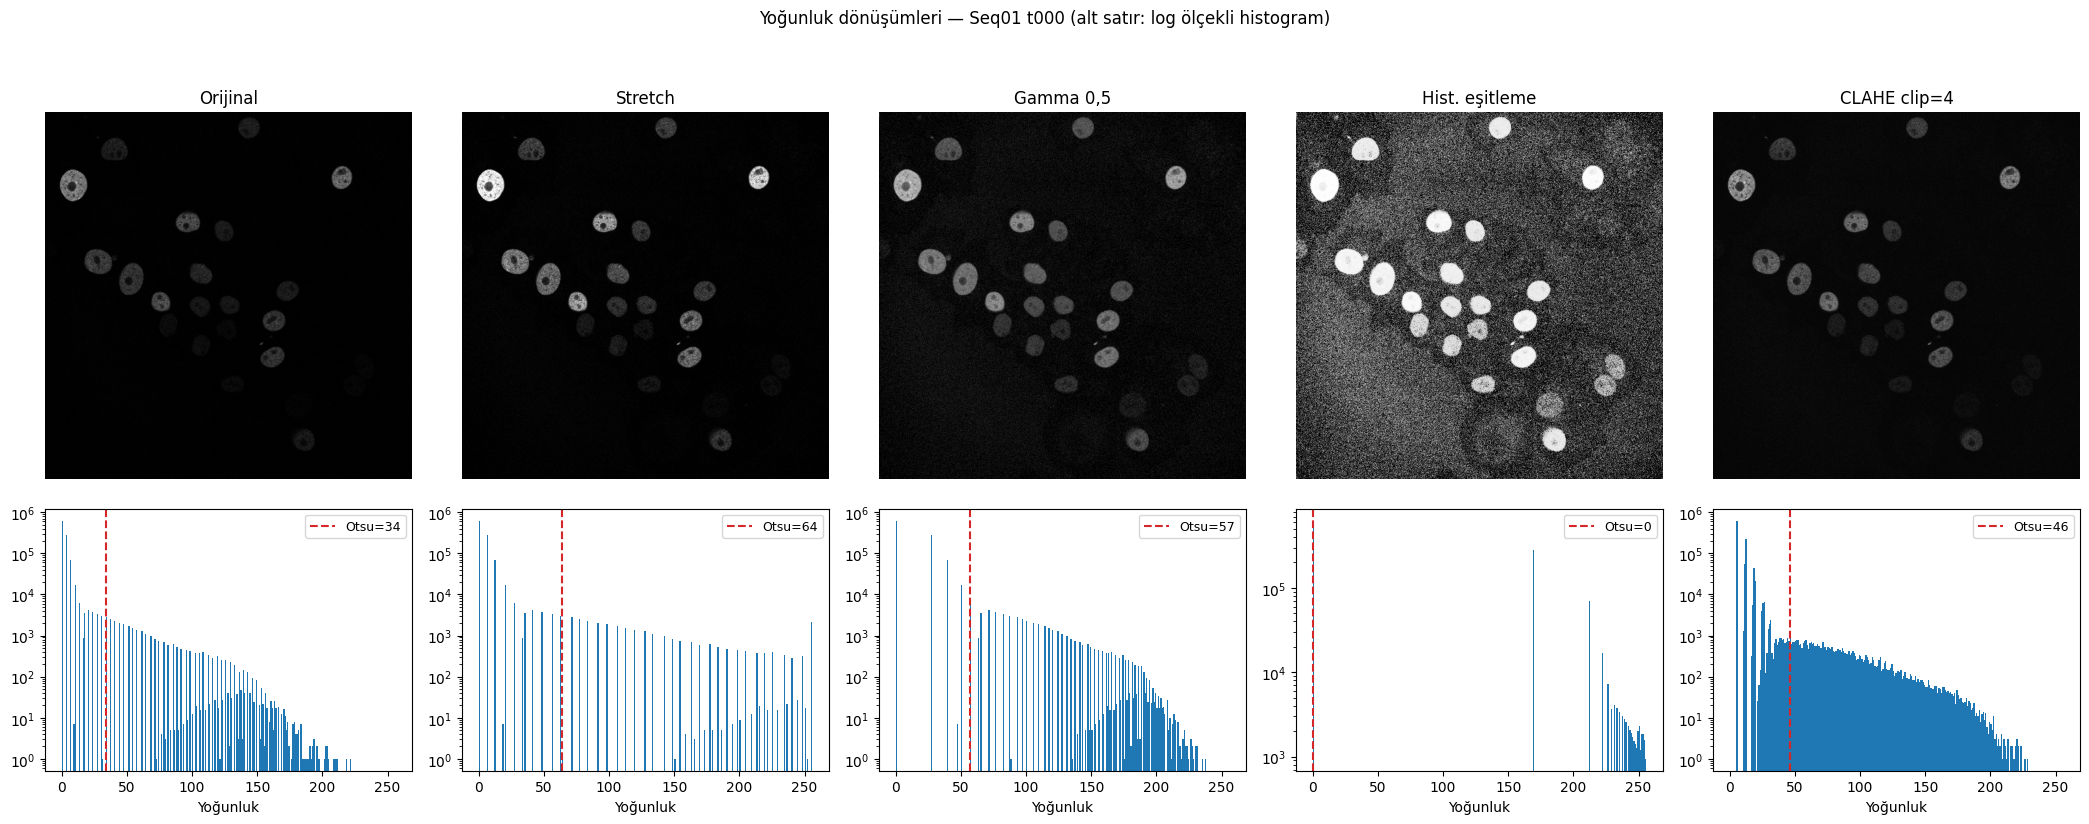

In [28]:
t = dev_frames[0]; img = DEV_IMGS[t]
show = [('Orijinal', img), ('Stretch', t_stretch(img)), ('Gamma 0,5', t_gamma(img, .5)),
        ('Hist. eşitleme', t_he(img)), ('CLAHE clip=4', t_clahe(img, 4.0))]
fig, axes = plt.subplots(2, len(show), figsize=(4.2 * len(show), 8.2), gridspec_kw={'height_ratios': [1, .55]})
for j, (name, x) in enumerate(show):
    axes[0, j].imshow(x, cmap='gray', vmin=0, vmax=255); axes[0, j].set_title(name); axes[0, j].axis('off')
    axes[1, j].hist(x.ravel(), bins=256, range=(0, 256), color='tab:blue', log=True)
    th = cv2.threshold(x, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[0]
    axes[1, j].axvline(th, c='tab:red', ls='--', label=f'Otsu={th:.0f}'); axes[1, j].legend(fontsize=9)
    axes[1, j].set_xlabel('Yoğunluk')
plt.suptitle(f'Yoğunluk dönüşümleri — Seq01 t{t:03d} (alt satır: log ölçekli histogram)', y=1.0)
plt.tight_layout(); plt.savefig(PRIVATE_FIG_DIR / 'fig2_intensity_transforms.png', dpi=110); plt.show()

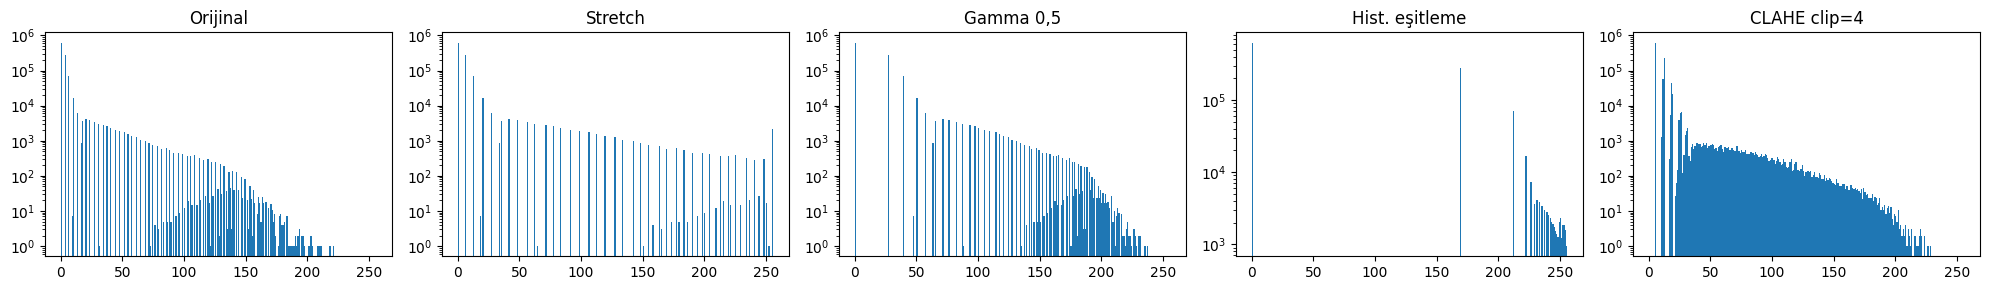

In [29]:
# Histogramlar tek başına (veri görüntüsü içermez → GitHub'a gidebilir)
fig, axes = plt.subplots(1, len(show), figsize=(4 * len(show), 3))
for ax, (name, x) in zip(axes, show):
    ax.hist(x.ravel(), bins=256, range=(0, 256), log=True); ax.set_title(name)
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig2b_intensity_histograms.png', dpi=130); plt.show()

**Gözlem notları (sonuçlardan sonra doldurulacak):**
- Histogram eşitleme: piksellerin %57'si 0 olduğu için ...
- Gamma: ...
- CLAHE: ...

## 7. Filtreleme deneyleri (Ödev Bölüm 7)

| Kod | Filtre | Beklenti (deneyden önce yazıldı) |
|---|---|---|
| E00 | Filtresiz (= baseline) | Referans |
| E06 | Gaussian 3×3 | Gürültüyü ortalar → parçalanma azalır |
| E07 | Gaussian 5×5 | Daha güçlü yumuşatma → parçalanma daha da azalır |
| E08 | Gaussian 9×9 | Hücreler arası ince boşluklar dolabilir → birleşme başlar mı? |
| E09 | Median 3×3 | Tuz-biber türü gürültüyü kenarları koruyarak temizler |
| E10 | Median 5×5 | Daha güçlü median |
| E11 | Keskinleştirme (unsharp mask, σ=2, miktar=1,0) | Farkları büyütür → parçalanma artar |

Yoğunluk, segmentasyon, morfoloji ve min alan baseline'daki gibi sabit tutulur; yalnızca filtre değişir.

In [30]:
def f_gaussian(img, k=3):
    return cv2.GaussianBlur(img, (k, k), 0)          # sigma=0: OpenCV kernel boyutundan hesaplar

def f_median(img, k=3):
    return cv2.medianBlur(img, k)

def f_unsharp(img, sigma=2.0, amount=1.0):
    """Keskinleştirme: orijinal + miktar × (orijinal − bulanık)"""
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    return cv2.addWeighted(img, 1 + amount, blur, -amount, 0)

FILTERS.update({'gaussian': f_gaussian, 'median': f_median, 'unsharp': f_unsharp})

FILTER_EXPS = [
    ('E06', ('gaussian', {'k': 3})),
    ('E07', ('gaussian', {'k': 5})),
    ('E08', ('gaussian', {'k': 9})),
    ('E09', ('median', {'k': 3})),
    ('E10', ('median', {'k': 5})),
    ('E11', ('unsharp', {'sigma': 2.0, 'amount': 1.0})),
]
for eid, step in FILTER_EXPS:
    log_experiment(eid, 'Filtre', cfg_with(filter=step))
cols = ['ID', 'Filtre', 'Count_MAE', 'RMSE', 'Bias', 'Bulunan', 'Parçalanma', 'BoşTespit', 'Birleşme', 'Süre_ms']
pd.DataFrame(EXPERIMENTS).query("ID == 'E00' or Grup == 'Filtre'")[cols]

,ID,Filtre,Count_MAE,RMSE,Bias,Bulunan,Parçalanma,BoşTespit,Birleşme,Süre_ms
0,E00,none,5.5,6.301,0.9,138/225,88,8,0,18.4
6,E06,gaussian(k=3),6.2,7.043,-0.2,137/225,75,11,0,13.4
7,E07,gaussian(k=5),4.6,6.340,-2.6,136/225,56,7,0,13.9
8,E08,gaussian(k=9),4.8,6.986,-4.2,135/225,41,7,0,14.5
9,E09,median(k=3),4.4,4.669,1.6,143/225,91,7,0,12.8
10,E10,median(k=5),4.7,6.269,-1.7,138/225,62,8,0,13.9
11,E11,"unsharp(sigma=2.0, amount=1.0)",10.3,11.158,7.3,132/225,151,15,0,16.6


### 7.1 Filtrelerin bir hücre üzerindeki etkisi

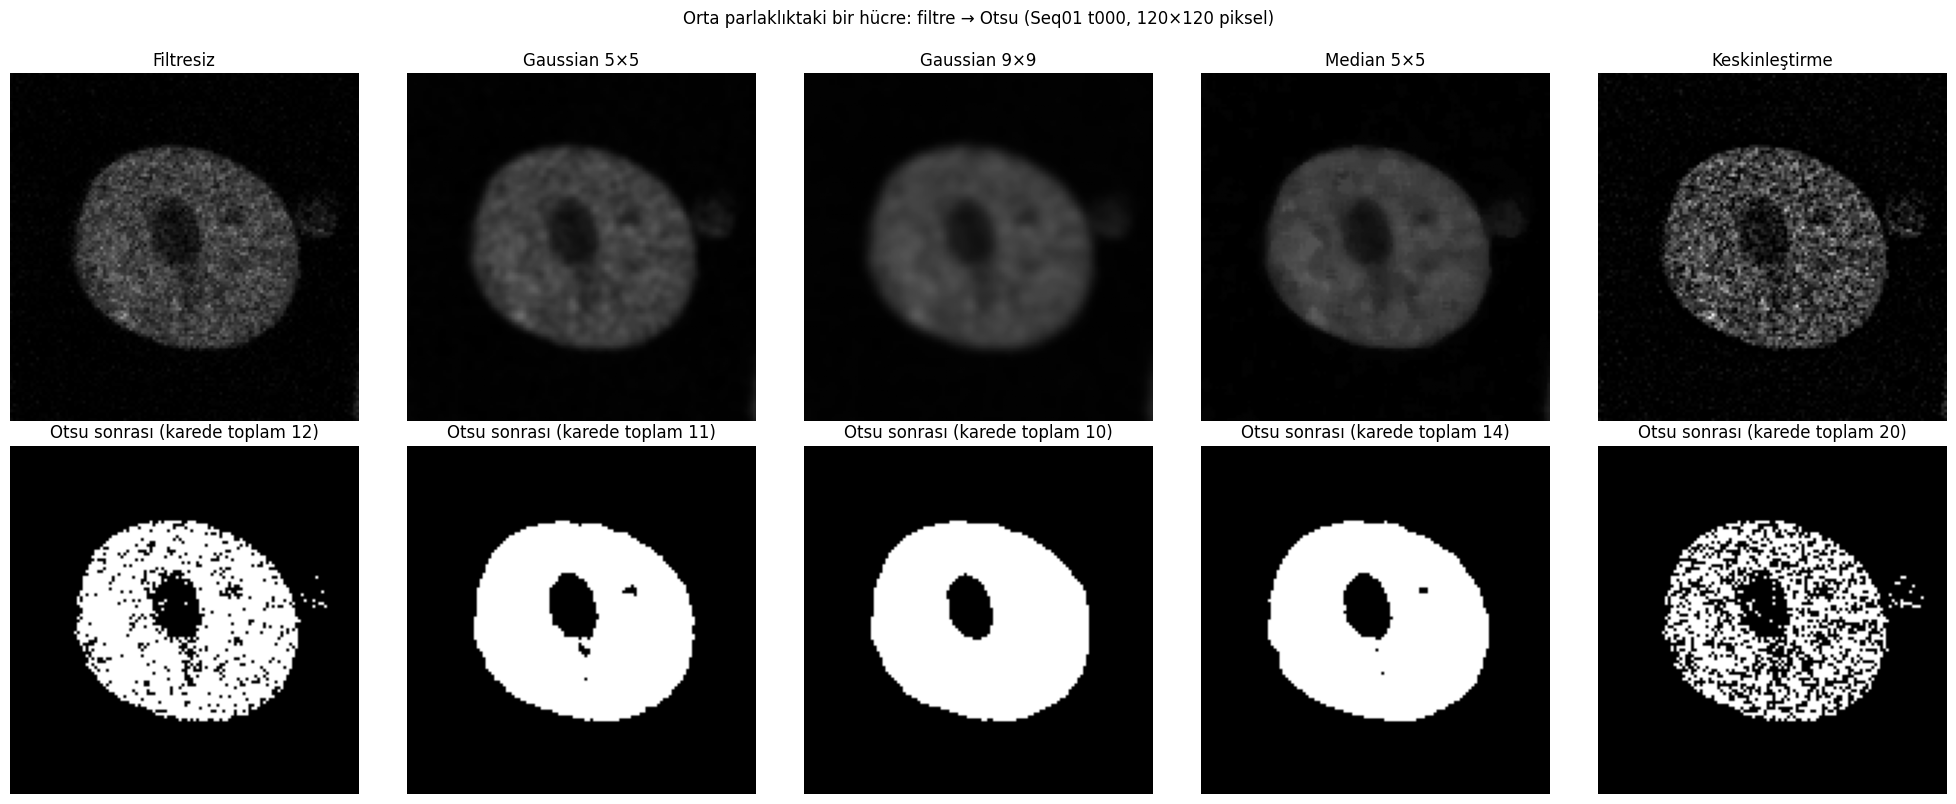

In [31]:
t = dev_frames[0]; img = DEV_IMGS[t]
tra = tifffile.imread(DATASET_DIR / '01_GT' / 'TRA' / f'man_track{t:03d}.tif')
# orta parlaklıkta bir hücre seç: ortalaması Otsu eşiğine en yakın olan
th0 = baseline_segment(img)[1]
ids = [i for i in np.unique(tra) if i]
cy, cx = [int(v) for v in ndi.center_of_mass(tra > 0, tra, ids)[int(np.argmin([abs(img[ndi.binary_dilation(tra == i, iterations=20)].mean() - th0) for i in ids]))]]
y0, x0 = max(cy - 60, 0), max(cx - 60, 0)
filters_show = [('Filtresiz', ('none', {})), ('Gaussian 5×5', ('gaussian', {'k': 5})), ('Gaussian 9×9', ('gaussian', {'k': 9})),
                ('Median 5×5', ('median', {'k': 5})), ('Keskinleştirme', ('unsharp', {'sigma': 2.0, 'amount': 1.0}))]
fig, axes = plt.subplots(2, len(filters_show), figsize=(4 * len(filters_show), 8))
for j, (name, step) in enumerate(filters_show):
    n, lab, stg = run_pipeline(img, cfg_with(filter=step), return_stages=True)
    axes[0, j].imshow(stg['filter'][y0:y0 + 120, x0:x0 + 120], cmap='gray', vmin=0, vmax=img.max()); axes[0, j].set_title(name)
    axes[1, j].imshow(stg['binary'][y0:y0 + 120, x0:x0 + 120], cmap='gray'); axes[1, j].set_title(f'Otsu sonrası (karede toplam {n})')
for a in axes.ravel(): a.axis('off')
plt.suptitle(f'Orta parlaklıktaki bir hücre: filtre → Otsu (Seq01 t{t:03d}, 120×120 piksel)', y=1.0)
plt.tight_layout(); plt.savefig(PRIVATE_FIG_DIR / 'fig_filters_zoom.png', dpi=110); plt.show()

## 8. Segmentasyon deneyleri (Ödev Bölüm 8)

| Kod | Yöntem | Beklenti / gerekçe |
|---|---|---|
| E00 | Global Otsu (= baseline) | Tek eşik: sönük hücreleri kaçırır, orta parlaklıktakileri parçalar |
| E12 | Sabit eşik T=10 | Arka plan tavanının (~2,6) belirgin üstü; sönük hücreleri yakalar ama gürültüyü de alabilir |
| E13 | Sabit eşik T=20 | Daha muhafazakâr sabit eşik |
| E14 | Adaptif (ortalama, blok=51, C=0) | **Tuzak deneyi:** hücresiz pencerelerde de piksellerin ~yarısı "yerel ortalamadan parlak" → gürültü hücre sayılır |
| E15 | Adaptif (ortalama, blok=101, C=−10) | Pencere ~1,5 hücre çapında; eşik = yerel ortalama + 10 (gürültüye pay) |
| E16 | Adaptif (Gaussian ağırlıklı, blok=101, C=−10) | Yerel ortalamayı merkeze ağırlık vererek hesaplar |
| E17 | Multi-Otsu, 3 sınıf (alt eşik) | Hocanın ipucu: arka plan / sönük hücre / parlak hücre. Alt eşiğin üstü = hücre |
| E18 | Multi-Otsu, 4 sınıf (alt eşik) | Daha ince ayrım: alt eşik daha da düşer |
| E19 | Hysteresis (düşük=8, yüksek=Otsu) | Yüksek eşiği geçen bölgeler tohum, düşük eşiği geçen ve tohuma bağlı pikseller hücreye eklenir |

Not: OpenCV `adaptiveThreshold`'ta eşik = yerel ortalama − C'dir. Yani C=−10, "yerel ortalamanın 10 birim üstü" demektir.
Parametre değerleri yalnızca geliştirme verisi üzerinde yapılan ön incelemeyle belirlenmiştir.

In [32]:
from skimage.filters import threshold_multiotsu, apply_hysteresis_threshold

def s_fixed(img, T=20):
    return img > T

def s_adaptive(img, method='mean', block=51, C=0):
    m = cv2.ADAPTIVE_THRESH_MEAN_C if method == 'mean' else cv2.ADAPTIVE_THRESH_GAUSSIAN_C
    return cv2.adaptiveThreshold(img, 255, m, cv2.THRESH_BINARY, block, C) > 0

def s_multiotsu(img, classes=3):
    """Çok seviyeli Otsu: sınıflar arası varyansı maksimize eden (classes−1) eşik. En alt eşiğin üstü = hücre."""
    return img > threshold_multiotsu(img, classes=classes)[0]

def s_hysteresis(img, low=8, high='otsu'):
    hi = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[0] if high == 'otsu' else high
    return apply_hysteresis_threshold(img, low, hi)

SEGMENT.update({'fixed': s_fixed, 'adaptive': s_adaptive, 'multiotsu': s_multiotsu, 'hysteresis': s_hysteresis})

SEG_EXPS = [
    ('E12', ('fixed', {'T': 10}), ''),
    ('E13', ('fixed', {'T': 20}), ''),
    ('E14', ('adaptive', {'method': 'mean', 'block': 51, 'C': 0}), 'tuzak deneyi: gürültü payı yok'),
    ('E15', ('adaptive', {'method': 'mean', 'block': 101, 'C': -10}), ''),
    ('E16', ('adaptive', {'method': 'gaussian', 'block': 101, 'C': -10}), ''),
    ('E17', ('multiotsu', {'classes': 3}), 'hocanın çoklu eşik önerisi'),
    ('E18', ('multiotsu', {'classes': 4}), ''),
    ('E19', ('hysteresis', {'low': 8, 'high': 'otsu'}), ''),
]
for eid, step, note in SEG_EXPS:
    log_experiment(eid, 'Segmentasyon', cfg_with(segment=step), note)
cols = ['ID', 'Segmentasyon', 'Count_MAE', 'RMSE', 'Bias', 'Bulunan', 'Parçalanma', 'BoşTespit', 'Birleşme', 'Süre_ms']
pd.DataFrame(EXPERIMENTS).query("ID == 'E00' or Grup == 'Segmentasyon'")[cols]

,ID,Segmentasyon,Count_MAE,RMSE,Bias,Bulunan,Parçalanma,BoşTespit,Birleşme,Süre_ms
0,E00,otsu,5.5,6.301,0.9,138/225,88,8,0,18.4
12,E12,fixed(T=10),5.0,5.710,4.8,199/225,39,35,0,11.0
13,E13,fixed(T=20),3.0,3.950,0.6,171/225,52,8,0,10.7
14,E14,"adaptive(method=mean, block=51, C=0)",1013.1,1021.678,1013.1,225/225,24,10109,2,28.4
15,E15,"adaptive(method=mean, block=101, C=-10)",4.3,5.050,2.3,190/225,46,12,0,20.9
16,E16,"adaptive(method=gaussian, block=101, C=-10)",13.3,14.110,13.3,177/225,163,18,0,46.4
17,E17,multiotsu(classes=3),2.4,3.066,0.0,170/225,47,8,0,16.7
18,E18,multiotsu(classes=4),3.6,4.313,2.6,192/225,43,16,0,50.4
19,E19,"hysteresis(low=8, high=otsu)",1.9,2.168,-0.1,195/225,3,26,0,35.3


In [33]:
# Multi-Otsu eşikleri: her geliştirme karesinde tek Otsu ile karşılaştırma
rows = []
for t in dev_frames:
    im = DEV_IMGS[t]
    rows.append({'frame': t, 'Otsu': cv2.threshold(im, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[0],
                 'MultiOtsu-3': threshold_multiotsu(im, 3).tolist(), 'MultiOtsu-4': threshold_multiotsu(im, 4).tolist()})
pd.DataFrame(rows)

,frame,Otsu,MultiOtsu-3,MultiOtsu-4
0,0,34.0,"[20, 72]","[13, 44, 89]"
1,1,35.0,"[20, 71]","[13, 44, 89]"
2,5,35.0,"[20, 72]","[13, 40, 86]"
3,37,30.0,"[20, 68]","[13, 40, 83]"
4,39,30.0,"[20, 68]","[13, 40, 83]"
5,44,31.0,"[20, 72]","[13, 42, 85]"
6,85,34.0,"[23, 83]","[13, 44, 96]"
7,86,34.0,"[23, 81]","[13, 44, 93]"
8,88,37.0,"[23, 86]","[16, 47, 98]"
9,89,37.0,"[23, 86]","[16, 47, 98]"


### 8.1 Segmentasyon yöntemlerinin görsel karşılaştırması (Şekil 3'ün bir parçası)

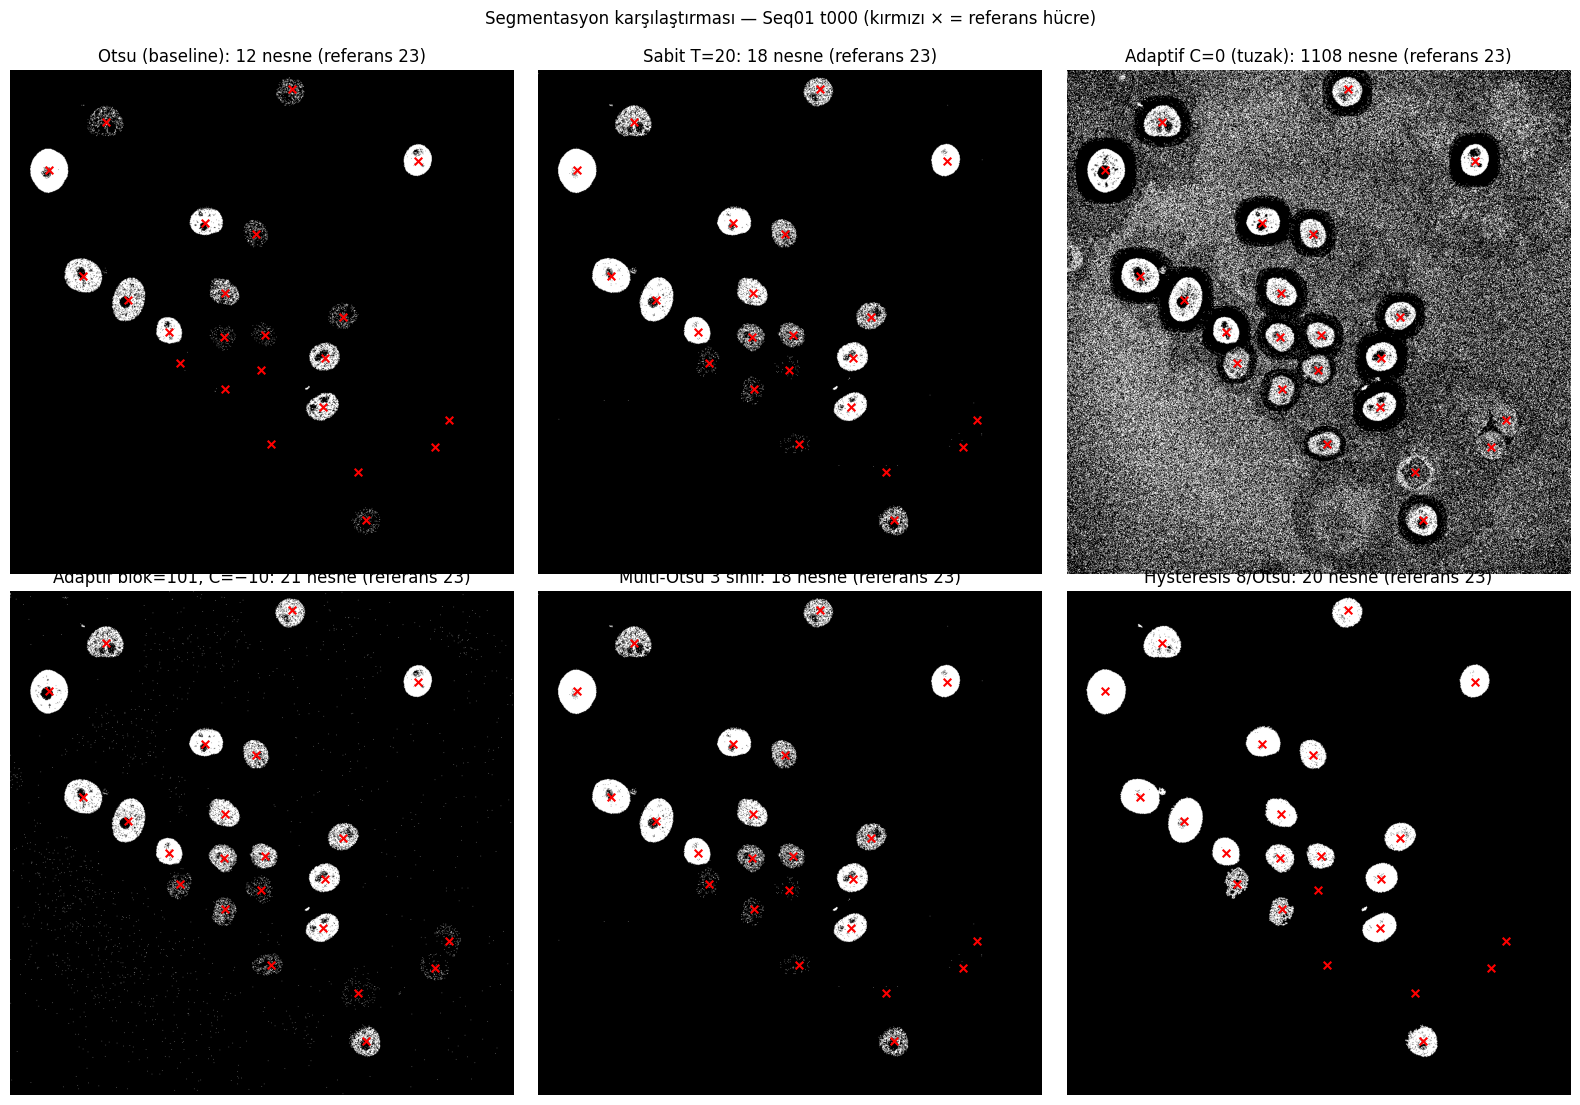

In [34]:
t = dev_frames[0]; img = DEV_IMGS[t]
seg_show = [('Otsu (baseline)', ('otsu', {})), ('Sabit T=20', ('fixed', {'T': 20})),
            ('Adaptif C=0 (tuzak)', ('adaptive', {'method': 'mean', 'block': 51, 'C': 0})),
            ('Adaptif blok=101, C=−10', ('adaptive', {'method': 'mean', 'block': 101, 'C': -10})),
            ('Multi-Otsu 3 sınıf', ('multiotsu', {'classes': 3})), ('Hysteresis 8/Otsu', ('hysteresis', {'low': 8, 'high': 'otsu'}))]
cen = tra_centroids('01', t)
fig, axes = plt.subplots(2, 3, figsize=(16, 11))
for ax, (name, step) in zip(axes.ravel(), seg_show):
    n, lab, stg = run_pipeline(img, cfg_with(segment=step), return_stages=True)
    ax.imshow(stg['binary'], cmap='gray'); ax.scatter(cen[:, 1], cen[:, 0], s=30, c='red', marker='x')
    ax.set_title(f'{name}: {n} nesne (referans {REF[("01", t)]})'); ax.axis('off')
plt.suptitle(f'Segmentasyon karşılaştırması — Seq01 t{t:03d} (kırmızı × = referans hücre)', y=1.0)
plt.tight_layout(); plt.savefig(PRIVATE_FIG_DIR / 'fig3a_segmentation_compare.png', dpi=100); plt.show()